# SVD Lab — Satellite Image Compression

In this lab we explore applications of **Singular Value Decomposition (SVD)** on satellite images.

**Goals**
1. Run SVD on a local satellite image and inspect singular values.
2. Check how many leading components are enough for a decent reconstruction.
3. Compare reconstruction from the **largest** `k` components vs components starting from the **10th** (`10 … k+10`).
4. Compare different terrains: **urban / forest / ocean** — how many components avoid perceptual degradation?
5. Record observations so results are visible in the notebook (for Git review).


## 0. Setup


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from PIL import Image

%matplotlib inline
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["image.cmap"] = "gray"


In [ ]:
DATA = Path("data")
assert DATA.exists(), f"Missing data folder: {DATA.resolve()}"

IMAGE_PATHS = {
    "urban": DATA / "urban.jpeg",   
    "forest": DATA / "forest.jpeg", 
    "ocean": DATA / "ocean.jpeg",  
}

for name, path in IMAGE_PATHS.items():
    assert path.exists(), f"Missing {name} image: {path.resolve()}"
    print(f"{name:8s} -> {path} ({path.stat().st_size / 1024:.1f} KB)")


urban    -> data/urban.jpeg (420.1 KB)
forest   -> data/forest.jpeg (232.8 KB)
ocean    -> data/ocean.jpeg (81.6 KB)


## Helper functions


In [3]:
def load_gray_matrix(path):
    """Load image as grayscale float matrix (rows x cols)."""
    img = Image.open(path).convert("L")
    mat = np.asarray(img, dtype=float)
    return mat


def svd_reconstruct(U, sigma, V, j, i):
    """Reconstruct image using singular components with indices [j, i)."""
    if i <= j:
        raise ValueError("Need i > j")
    return (U[:, j:i] * sigma[j:i]) @ V[j:i, :]


def show_gray(mat, title=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    ax.imshow(mat, cmap="gray")
    ax.set_title(title or "")
    ax.axis("off")
    return ax


## 1. Baseline: SVD on an urban satellite image

We start with `data/urban.jpeg` (Warsaw region). Convert to grayscale so the image is a 2D matrix.


shape: (1024, 1024)


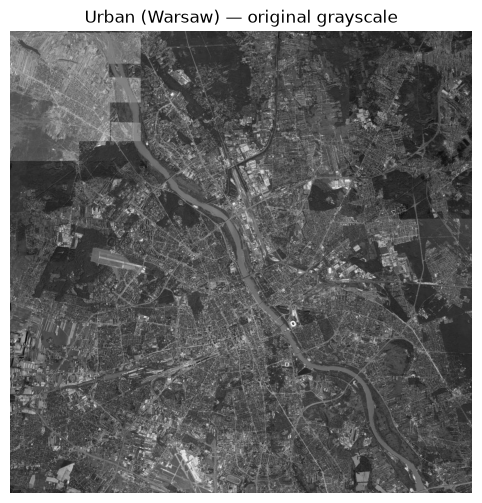

In [4]:
urban = load_gray_matrix(IMAGE_PATHS["urban"])
print("shape:", urban.shape)
show_gray(urban, "Urban (Warsaw) — original grayscale")
plt.show()


U: (1024, 1024) sigma: (1024,) Vh: (1024, 1024)


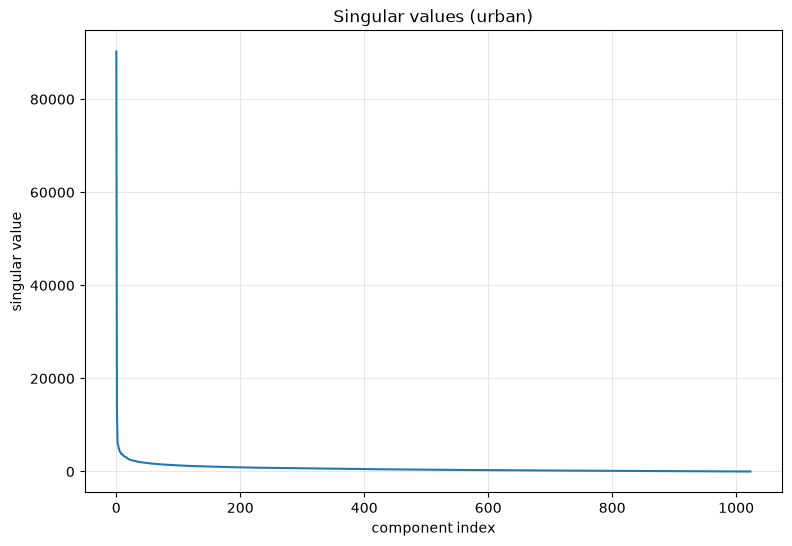

k=  5  cumulative energy = 92.33%
k= 20  cumulative energy = 94.35%
k= 50  cumulative energy = 95.90%
k= 70  cumulative energy = 96.53%
k=100  cumulative energy = 97.21%
k=200  cumulative energy = 98.49%


In [5]:
U, sigma, Vh = np.linalg.svd(urban, full_matrices=False)
print("U:", U.shape, "sigma:", sigma.shape, "Vh:", Vh.shape)

plt.figure()
plt.plot(sigma)
plt.xlabel("component index")
plt.ylabel("singular value")
plt.title("Singular values (urban)")
plt.grid(True, alpha=0.3)
plt.show()

# cumulative energy
energy = np.cumsum(sigma**2) / np.sum(sigma**2)
for k in [5, 20, 50, 70, 100, 200]:
    if k < len(energy):
        print(f"k={k:3d}  cumulative energy = {100*energy[k-1]:5.2f}%")


### Observation — singular values (urban)

The singular-value curve drops **very fast**: the first few values dominate, then a long near-zero tail.

So most image energy sits in a small number of leading components. Keeping all ~1000 components is unnecessary for a visually good reconstruction.


## 2. How many components are “good enough”?

Reconstruct with the largest `k` components (`j=0`, `i=k`) for several `k`.


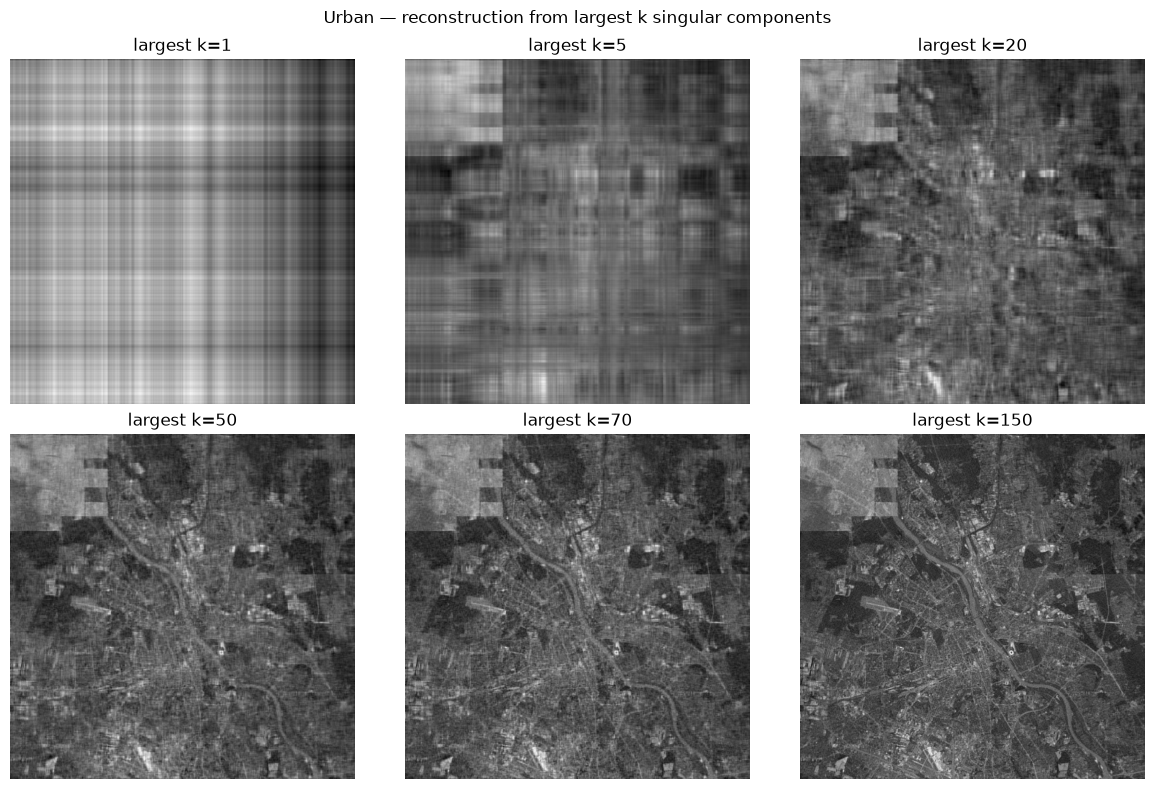

In [6]:
ks = [1, 5, 20, 50, 70, 150]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, k in zip(axes.ravel(), ks):
    rec = svd_reconstruct(U, sigma, Vh, j=0, i=k)
    show_gray(rec, f"largest k={k}", ax=ax)
plt.suptitle("Urban — reconstruction from largest k singular components")
plt.tight_layout()
plt.show()


### Observation — how many eigenvalues / singular values are enough?

For this urban scene:
- `k=1…5`: only coarse light/dark structure
- `k≈20`: city layout starts to appear
- `k≈50–70`: already perceptually close to the original for this lab
- `k≥150`: little visible gain vs. 70 for casual inspection

**Answer:** about **50–70** leading singular values are good enough for the urban image without strong perceptual degradation.


## 3. Largest `k` vs components `10 … k+10`

Assignment question: instead of the largest `k` values, if we use the 10th, 11th, …, `(k+10)`th components, do we get **better** images?

We compare side-by-side for the same number of components `k`.


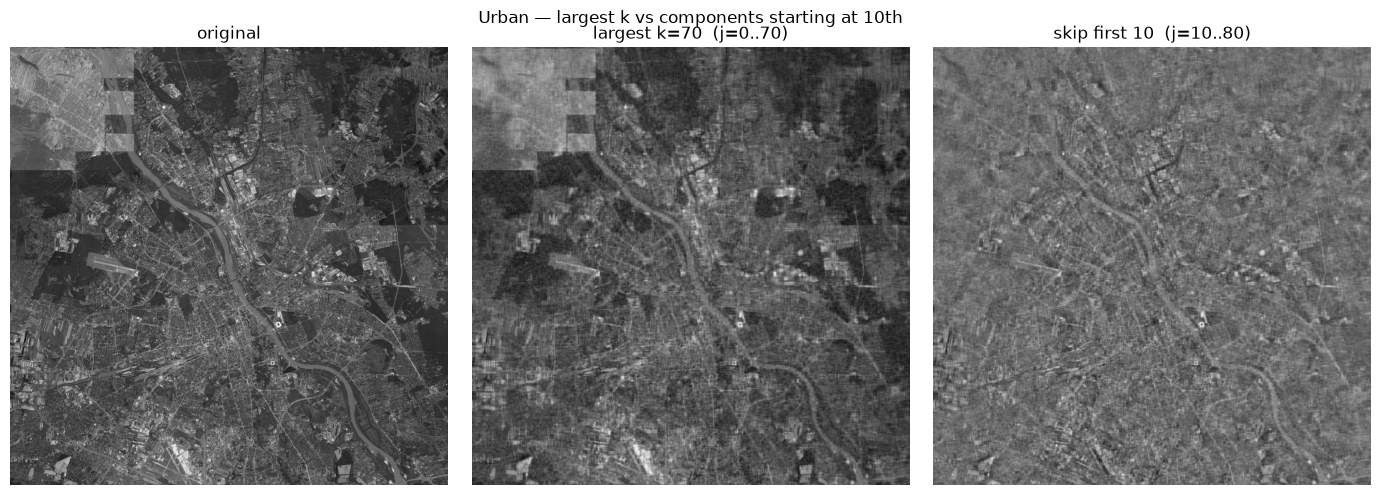

relative Frobenius error (largest k): 0.1863
relative Frobenius error (skip 10):   0.9822


In [7]:
k = 70
rec_largest = svd_reconstruct(U, sigma, Vh, j=0, i=k)          # 0 .. 69  (largest k)
rec_skip10  = svd_reconstruct(U, sigma, Vh, j=10, i=k + 10)    # 10 .. 79 (skip first 10)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
show_gray(urban, "original", axes[0])
show_gray(rec_largest, f"largest k={k}  (j=0..{k})", axes[1])
show_gray(rec_skip10, f"skip first 10  (j=10..{k+10})", axes[2])
plt.suptitle("Urban — largest k vs components starting at 10th")
plt.tight_layout()
plt.show()

err_largest = np.linalg.norm(urban - rec_largest) / np.linalg.norm(urban)
err_skip10  = np.linalg.norm(urban - rec_skip10)  / np.linalg.norm(urban)
print(f"relative Frobenius error (largest k): {err_largest:.4f}")
print(f"relative Frobenius error (skip 10):   {err_skip10:.4f}")


### Observation — skipping the first 10 components

**No — we do not get better images.** We get **worse** ones.

Reason: SVD ranks components by importance. The first singular values carry global brightness and the main low-frequency structure. Dropping them and taking `10 … k+10` removes the most informative directions, so contrast and overall layout degrade even if we keep the same count `k` of components.

Relative reconstruction error is also higher when the leading 10 are omitted.


## 4. Different terrains: forest vs urban vs ocean

Load three satellite scenes and, for each, find roughly how many leading singular values keep the image without clear perceptual degradation.


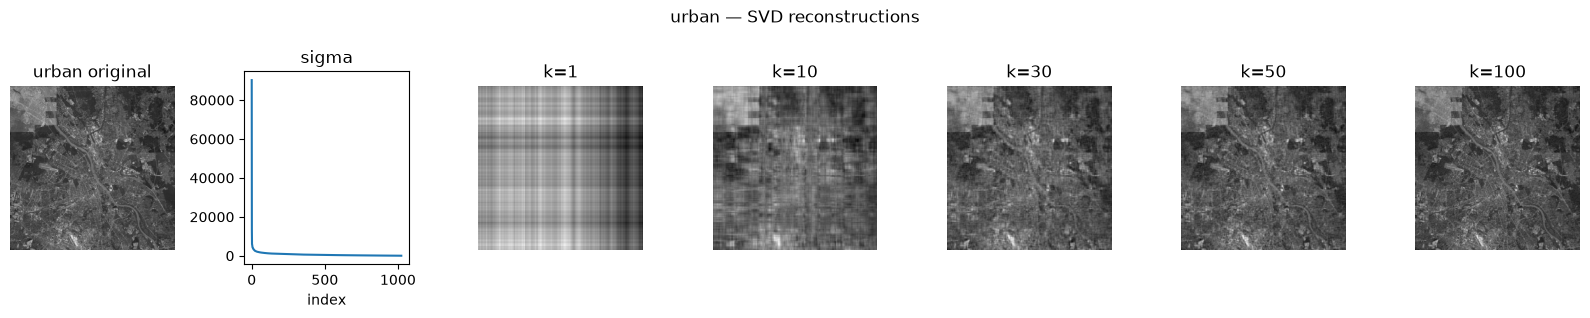

[urban] shape=(1024, 1024)  k@95% energy=30  k@99% energy=273


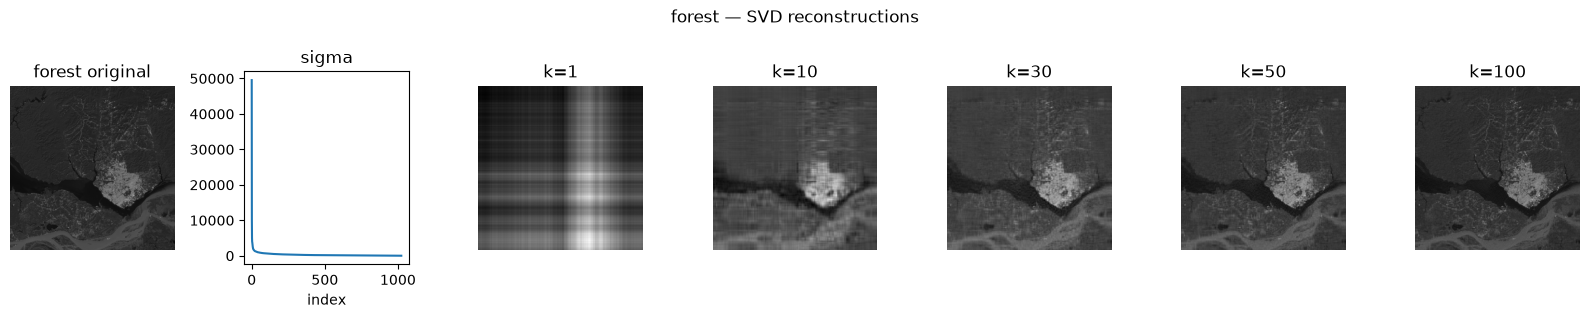

[forest] shape=(1024, 1024)  k@95% energy=10  k@99% energy=164


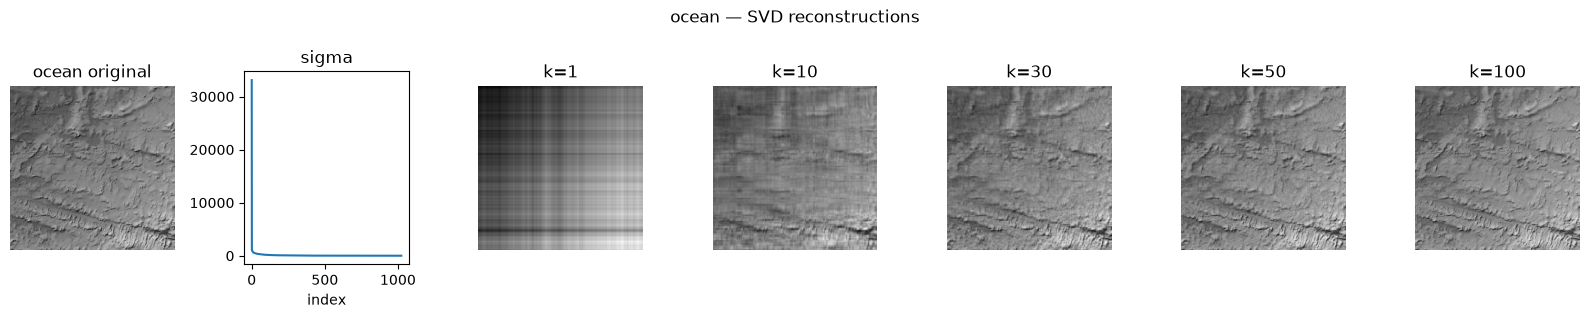

[ocean] shape=(1024, 1024)  k@95% energy=1  k@99% energy=13


In [8]:
def analyze_terrain(name, path, ks=(1, 10, 30, 50, 100)):
    mat = load_gray_matrix(path)
    U, s, Vh = np.linalg.svd(mat, full_matrices=False)
    energy = np.cumsum(s**2) / np.sum(s**2)

    # k needed for 95% / 99% energy
    k95 = int(np.searchsorted(energy, 0.95) + 1)
    k99 = int(np.searchsorted(energy, 0.99) + 1)

    fig, axes = plt.subplots(1, len(ks) + 2, figsize=(16, 3.2))
    show_gray(mat, f"{name} original", axes[0])
    axes[1].plot(s)
    axes[1].set_title("sigma")
    axes[1].set_xlabel("index")
    for ax, k in zip(axes[2:], ks):
        rec = svd_reconstruct(U, s, Vh, 0, k)
        show_gray(rec, f"k={k}", ax)
    plt.suptitle(f"{name} — SVD reconstructions")
    plt.tight_layout()
    plt.show()

    print(f"[{name}] shape={mat.shape}  k@95% energy={k95}  k@99% energy={k99}")
    return {"name": name, "k95": k95, "k99": k99, "sigma": s}


summaries = []
for name, path in IMAGE_PATHS.items():
    summaries.append(analyze_terrain(name, path))


In [9]:
print("Terrain comparison (energy-based ranks):")
print(f"{'terrain':8s}  {'k@95%':>6s}  {'k@99%':>6s}")
for s in summaries:
    print(f"{s['name']:8s}  {s['k95']:6d}  {s['k99']:6d}")


Terrain comparison (energy-based ranks):
terrain    k@95%   k@99%
urban         30     273
forest        10     164
ocean          1      13


### Observation — terrain comparison

| Terrain | What we see | Typical # of components |
|---|---|---|
| **Ocean** | Mostly smooth / low texture | Fewest components needed |
| **Forest** | Repeated canopy texture | Mid range |
| **Urban** | Sharp edges, streets, buildings | Most components needed |

**Why?** SVD (low-rank approx.) is cheaper when the image has less spatial complexity. Open ocean is nearly low-rank; cities need more singular vectors to keep fine structure without blur.

**Practical takeaway for this lab:** ocean often looks fine around lower `k`; urban needs higher `k` (tens) before it stops looking degraded.


## 5. Final conclusions

1. Singular values of satellite images decay quickly → strong compression potential via truncated SVD.
2. For the urban Warsaw scene, roughly **50–70** leading components are enough for a decent look.
3. Using components **10 … k+10 instead of 0 … k does NOT improve quality** — it makes it worse, because the largest singular values matter most.
4. Terrain matters: **ocean < forest < urban** in how many components you need to avoid perceptual degradation.
5. All plots/images above are saved as notebook outputs so they remain visible after pushing to Git.
